# Does a stronger pose model make a better classifier? MediaPipe vs SAM 3D Body on arm abduction

The pilot showed that SAM 3D Body's joint angles agree across cameras about twice as well as MediaPipe's.
This notebook tests whether that carries over to the actual task: the same models, features and training
recipe, changing only where the poses come from.

- **Data:** every arm-abduction repetition of the four development participants, from all three cameras
  (443 repetitions, 1,329 sequences). The held-out test participant is not used.
- **Split:** each participant takes a turn as the unseen validation participant; three seeds.
- **Poses:** MediaPipe on every frame; SAM 3D Body in body-only mode on every third frame. Both are
  resampled to 64 time steps.
- **Like-for-like joints:** coordinate features use only the 17 body joints that both models estimate
  directly (nose, shoulders, elbows, wrists, hips, knees, ankles, heels, toes). Face and finger points are
  dropped because SAM 3D Body's were filled in from neighbouring joints.

All models here are trained on arm abduction only, so the MediaPipe rows are a new baseline and are not
directly comparable to the all-exercise numbers in the earlier notebooks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from rehab26.data import DATA_DIR, load_dataset, participant_folds
from rehab26.features import biomech_features, canonicalize_rotation, normalize_by_group, scale_normalize
from rehab26.sam3d import load_sam3d
from rehab26.train import run_condition, summarize_scores

SEEDS = (0, 1, 2)
FIG = "../docs/figures"
BODY = [0, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
pd.set_option("display.width", 220)

X, full_meta = load_dataset(n_frames=64)
P_sam, idx = load_sam3d(DATA_DIR / "sam3d/ex1", n_frames=64)
meta = full_meta.reset_index().merge(idx.assign(sam_row=np.arange(len(idx))), on=["rep_id", "cam"])
meta = meta.sort_values(["rep_id", "cam"]).reset_index(drop=True)
POSES = {"MediaPipe": X[meta["index"].values][..., :3], "SAM 3D Body": P_sam[meta.sam_row.values]}
FOLDS = participant_folds(meta, test_person="Vasil")

print("sequences:", len(meta), "| repetitions:", meta.rep_id.nunique(), "| incorrect share: %.2f" % meta.y.mean())
print("folds:", [(v, len(tr), len(va)) for tr, va, v in FOLDS])
print("SAM 3D Body frames:", int(meta.n_samples.sum()), "| failed:", int(meta.failed.sum()))
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

sequences: 1329 | repetitions: 443 | incorrect share: 0.50
folds: [('Honza', 999, 330), ('Mima', 993, 336), ('Petra', 996, 333), ('Terka', 999, 330)]
SAM 3D Body frames: 48258 | failed: 0
device: cuda


## 1. Features

Three feature sets, built identically from both pose sources:

- **scaled**: body-joint coordinates divided by torso length.
- **aligned**: scaled, then rotated about the vertical so the starting pose faces the camera.
- **biomech**: joint angles, segment tilts and width ratios with their velocities.

Each is also run with per-participant normalization (z-scoring every feature over all of a participant's
repetitions, without labels), the one treatment that helped in the person-gap experiments.

In [2]:
def features(P):
    n, t = P.shape[:2]
    scaled = scale_normalize(P)
    return {"scaled": scaled[:, :, BODY].reshape(n, t, -1),
            "aligned": canonicalize_rotation(scaled)[:, :, BODY].reshape(n, t, -1),
            "biomech": biomech_features(P)[0]}

FEATURES = {src: features(P) for src, P in POSES.items()}
KEYS, KINDS, NORMS = ("scaled", "aligned", "biomech"), ("mlp", "cnn"), ("none", "per-participant")
person = meta.person.values

all_scores, all_preds = [], []
for kind in KINDS:
    for key in KEYS:
        for norm in NORMS:
            for src in POSES:
                seq = FEATURES[src][key]
                if norm == "per-participant":
                    seq = normalize_by_group(seq, person)
                s, p, _ = run_condition(f"{kind.upper()} | {key} | {norm} | {src}", kind, seq, meta, FOLDS, SEEDS)
                tags = dict(model=kind.upper(), features=key, norm=norm, source=src)
                all_scores.append(s.assign(**tags)); all_preds.append(p.assign(**tags))
scores, preds = pd.concat(all_scores), pd.concat(all_preds)

MLP | scaled | none | MediaPipe          val acc 0.629  (12s)


MLP | scaled | none | SAM 3D Body        val acc 0.664  (10s)


MLP | scaled | per-participant | MediaPipe val acc 0.727  (10s)


MLP | scaled | per-participant | SAM 3D Body val acc 0.831  (10s)


MLP | aligned | none | MediaPipe         val acc 0.636  (10s)


MLP | aligned | none | SAM 3D Body       val acc 0.711  (10s)


... (14 outputs left out)

CNN | biomech | none | MediaPipe         val acc 0.660  (14s)


CNN | biomech | none | SAM 3D Body       val acc 0.732  (14s)


CNN | biomech | per-participant | MediaPipe val acc 0.732  (14s)


CNN | biomech | per-participant | SAM 3D Body val acc 0.838  (14s)


## 2. Results

Validation accuracy on the unseen participant, averaged over participants and seeds. `difference` is
SAM 3D Body minus MediaPipe; `folds_better` counts in how many of the four participants SAM 3D Body was
ahead.

In [3]:
G = ["model", "features", "norm"]
acc = scores.groupby(G + ["source"], sort=False).acc.mean().unstack()
acc["difference"] = acc["SAM 3D Body"] - acc["MediaPipe"]
by_person = scores.groupby(G + ["val_person", "source"], sort=False).acc.mean().unstack()
acc["folds_better"] = (by_person["SAM 3D Body"] > by_person["MediaPipe"]).groupby(G, sort=False).sum()
display(acc.round(3))

detail = scores.groupby(G + ["source"], sort=False)[["acc", "auc", "recall", "specificity", "train_loss", "val_loss"]].mean()
display(detail.round(3))
print("Mean over all 12 configurations:"); display(scores.groupby("source").acc.mean().round(3).to_frame().T)
print("Accuracy per unseen participant, mean over configurations:")
display(scores.groupby(["source", "val_person"]).acc.mean().unstack().round(3))
acc.to_csv("../docs/part5_sam3d_results.csv")

source                          MediaPipe  SAM 3D Body  difference  folds_better
model features norm                                                             
MLP   scaled   none                 0.629        0.664       0.035             2
               per-participant      0.727        0.831       0.104             3
      aligned  none                 0.636        0.711       0.075             2
               per-participant      0.740        0.828       0.088             3
      biomech  none                 0.637        0.733       0.096             4
               per-participant      0.683        0.854       0.171             4
CNN   scaled   none                 0.629        0.683       0.054             3
               per-participant      0.697        0.861       0.164             4
      aligned  none                 0.619        0.680       0.062             3
               per-participant      0.689        0.808       0.119             4
      biomech  none                 0.660        0.732       0.072             3
               per-participant      0.732        0.838       0.106             4

acc    auc  recall  specificity  train_loss  val_loss
model features norm            source                                                              
MLP   scaled   none            MediaPipe    0.629  0.767   0.771        0.486       0.176     1.838
                               SAM 3D Body  0.664  0.861   0.903        0.425       0.053     2.544
               per-participant MediaPipe    0.727  0.828   0.781        0.672       0.164     0.781
                               SAM 3D Body  0.831  0.904   0.876        0.786       0.044     0.687
      aligned  none            MediaPipe    0.636  0.775   0.767        0.505       0.135     1.961
                               SAM 3D Body  0.711  0.899   0.870        0.553       0.017     2.006
               per-participant MediaPipe    0.740  0.833   0.808        0.672       0.127     0.920
                               SAM 3D Body  0.828  0.917   0.909        0.746       0.016     0.855
      biomech  none            MediaPipe    0.637  0.736   0.807        0.466       0.076     2.025
                               SAM 3D Body  0.733  0.939   0.885        0.582       0.006     1.987
               per-participant MediaPipe    0.683  0.779   0.756        0.609       0.067     1.436
                               SAM 3D Body  0.854  0.942   0.914        0.794       0.006     0.778
CNN   scaled   none            MediaPipe    0.629  0.787   0.714        0.544       0.078     1.989
                               SAM 3D Body  0.683  0.911   0.885        0.481       0.042     1.478
               per-participant MediaPipe    0.697  0.823   0.821        0.574       0.077     1.189
                               SAM 3D Body  0.861  0.939   0.856        0.867       0.052     0.452
      aligned  none            MediaPipe    0.619  0.760   0.758        0.480       0.058     2.379
                               SAM 3D Body  0.680  0.878   0.793        0.568       0.020     2.103
               per-participant MediaPipe    0.689  0.787   0.789        0.590       0.054     1.469
                               SAM 3D Body  0.808  0.919   0.900        0.716       0.015     0.879
      biomech  none            MediaPipe    0.660  0.792   0.778        0.541       0.018     2.458
                               SAM 3D Body  0.732  0.934   0.918        0.546       0.007     1.933
               per-participant MediaPipe    0.732  0.834   0.788        0.676       0.022     1.319
                               SAM 3D Body  0.838  0.955   0.926        0.751       0.005     0.790

Mean over all 12 configurations:


source,MediaPipe,SAM 3D Body
acc,0.673,0.769


Accuracy per unseen participant, mean over configurations:


val_person,Honza,Mima,Petra,Terka
source,,,,
MediaPipe,0.610,0.641,0.756,0.685
SAM 3D Body,0.747,0.716,0.854,0.758


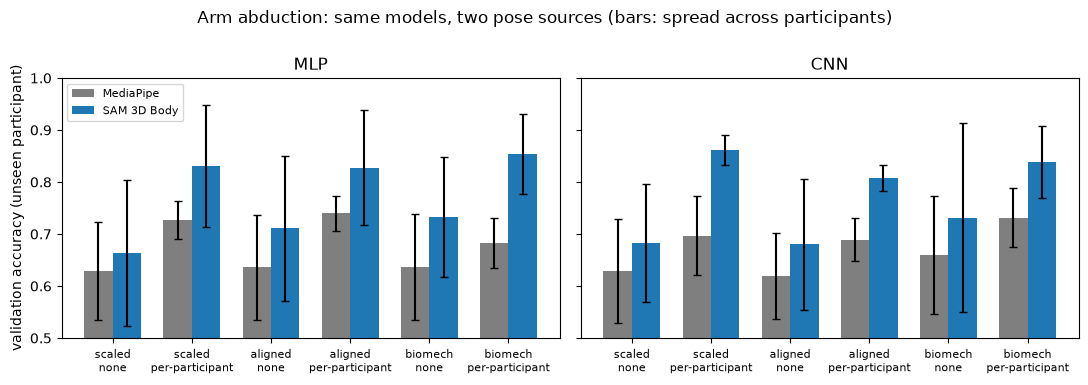

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = [f"{k}\n{n}" for k in KEYS for n in NORMS]
xpos = np.arange(len(labels))
std = scores.groupby(G + ["source", "val_person"], sort=False).acc.mean().groupby(G + ["source"], sort=False).std().unstack()
for ax, kind in zip(axes, KINDS):
    for off, src, color in [(-0.18, "MediaPipe", "tab:gray"), (0.18, "SAM 3D Body", "tab:blue")]:
        rows = [(kind.upper(), k, n) for k in KEYS for n in NORMS]
        ax.bar(xpos + off, acc.loc[rows, src], 0.36, yerr=std.loc[rows, src], capsize=3, color=color, label=src)
    ax.set_xticks(xpos); ax.set_xticklabels(labels, fontsize=8); ax.set_title(kind.upper()); ax.set_ylim(0.5, 1.0)
axes[0].set_ylabel("validation accuracy (unseen participant)"); axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Arm abduction: same models, two pose sources (bars: spread across participants)", y=1.0)
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p5_sources.png", dpi=150); plt.show()

## 3. Where the difference is

Accuracy by viewing angle (negative angles put the exercising arm on the far side from the camera), and
the share of each error type that is caught, pooled over all twelve configurations.

view_bin,-90 to -61,-60 to -31,-30 to -1,0 to 30,31 to 60,61 to 90
source,,,,,,
MediaPipe,0.558,0.674,0.642,0.709,0.720,0.677
SAM 3D Body,0.759,0.754,0.706,0.787,0.807,0.781


By view, best single configuration family (CNN, biomech):


view_bin                     -90 to -61  -60 to -31  -30 to -1  0 to 30  31 to 60  61 to 90
norm            source                                                                     
none            MediaPipe         0.555       0.658      0.611    0.670     0.719     0.730
                SAM 3D Body       0.696       0.721      0.723    0.755     0.746     0.713
per-participant MediaPipe         0.559       0.699      0.724    0.810     0.779     0.710
                SAM 3D Body       0.787       0.840      0.752    0.860     0.905     0.847

source,MediaPipe,SAM 3D Body,sequences,difference
error,,,,
correct,0.567,0.650,663,0.083
ERR_BENT_ARM,0.733,0.762,135,0.029
ERR_HEAD_TO_SIDE,0.749,0.882,135,0.133
ERR_ARM_FORWARD,0.790,0.937,132,0.148
ERR_ELEVATED_SHOULDER,0.721,0.902,132,0.181
ERR_LOW_ABDUCTION,0.902,0.951,132,0.049


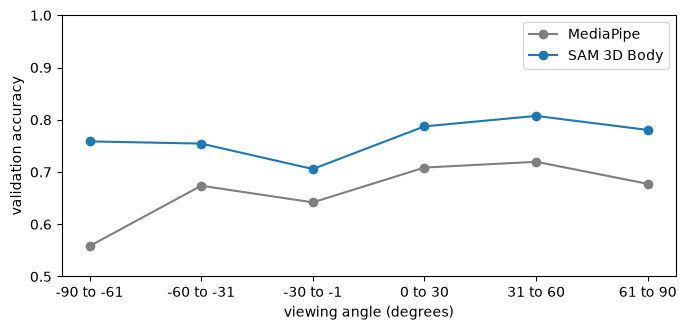

In [5]:
preds["hit"] = (preds.pred == preds.y).astype(float)
preds["view_bin"] = pd.cut(preds["view"], [-91, -60, -30, -1, 30, 60, 91],
                           labels=["-90 to -61", "-60 to -31", "-30 to -1", "0 to 30", "31 to 60", "61 to 90"])
by_view = preds.groupby(["source", "view_bin"], observed=True).hit.mean().unstack()
display(by_view.round(3))
print("By view, best single configuration family (CNN, biomech):")
display(preds[(preds.model == "CNN") & (preds.features == "biomech")]
        .groupby(["norm", "source", "view_bin"], observed=True).hit.mean().unstack().round(3))

per_error = preds.groupby(["error", "source"]).hit.mean().unstack()
per_error["sequences"] = meta.groupby("error").size()
per_error["difference"] = per_error["SAM 3D Body"] - per_error["MediaPipe"]
display(per_error.sort_values("sequences", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
for src, color in [("MediaPipe", "tab:gray"), ("SAM 3D Body", "tab:blue")]:
    ax.plot(by_view.columns.astype(str), by_view.loc[src], "o-", color=color, label=src)
ax.set_xlabel("viewing angle (degrees)"); ax.set_ylabel("validation accuracy"); ax.set_ylim(0.5, 1.0); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p5_view.png", dpi=150); plt.show()

## 4. Findings

**SAM 3D Body poses give a better classifier in every configuration.** Across the twelve combinations of
model, features and normalization, accuracy on an unseen participant rises from 0.673 to 0.769 on average.
The gain ranges from 0.04 to 0.17 and is positive every time. All four participants improve on average
(by 0.07 to 0.14), though in the weaker configurations without normalization only two or three of the four
do.

**The two fixes stack.** Per-participant normalization adds about 0.07 with MediaPipe poses and about 0.14
with SAM 3D Body poses. The best results are 0.861 (CNN, scaled coordinates) and 0.854 (MLP, biomechanical
features), both with SAM 3D Body and normalization. The best MediaPipe result is 0.740. Ranking quality
improves even more than accuracy: AUC goes from roughly 0.74 to 0.83 with MediaPipe to 0.86 to 0.96 with
SAM 3D Body.

**The far side is where it matters most.** With the exercising arm hidden from the camera (views of -90°
to -61°), MediaPipe models are near chance at 0.56 and SAM 3D Body models reach 0.76, the same level as
their other views. SAM 3D Body is also ahead in every other view group, by 0.06 to 0.10.

**Subtle errors gain the most.** Detection of elevated shoulder, arm forward and head to side rises by 0.13
to 0.18. Bent arm gains only 0.03, less than the pilot's elbow-angle indicator suggested. Correct
repetitions are still the weak spot: 65% pass on average, up from 57%, and 75 to 87% in the best
configurations.

**Models still memorize.** Training loss is near zero and validation loss is high without normalization,
for both pose sources. Better poses raise the ceiling but do not remove the participant gap.

### Limits

- Four participants and one exercise. Differences between participants are large (0.72 to 0.85 with
  SAM 3D Body), so the size of the gain is uncertain even though its direction is consistent.
- The best configuration was picked using these same validation participants, so 0.86 is optimistic. The
  average over configurations (0.77 against 0.67) is the safer comparison.
- Per-participant normalization assumes several unlabeled repetitions from the new person, and benefits
  from this dataset's even mix of correct and incorrect repetitions.
- SAM 3D Body takes about 0.18 s per frame on a laptop GPU, far from real time; MediaPipe runs live.
- The person box for SAM 3D Body came from MediaPipe's landmarks, so the pipeline still depends on MediaPipe
  for detection.

### Next step

Run SAM 3D Body on squat and shoulder extension so the full three-exercise comparison can be made, then
evaluate the chosen configuration once on the held-out participant.